In [15]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader
from protgen.data import AA, FAMILIES, IGNORE_INDEX, special_tokens

import matplotlib.pyplot as plt

In [16]:
train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Inddexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
val_loader = DataLoader(val_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [17]:
print(f"vocab ({train_data.vocab_size} tokens): {train_data.vocab}")
print(f"families: {train_data.fam_to_idx}")
print(f"padding is ignored in the loss with ignore_index={IGNORE_INDEX}")

sequence = train_data.df["sequence"][0]
tokens = train_data.encode(sequence)
print()
print(f"encode / decode round-trips: {train_data.decode(tokens) == sequence}")
print(f"and from the shifted target too:  {train_data.decode(x_shifted) == sequence}")

vocab (23 tokens): {'<PAD>': 0, '<BOS>': 1, '<EOS>': 2, 'A': 3, 'C': 4, 'D': 5, 'E': 6, 'F': 7, 'G': 8, 'H': 9, 'I': 10, 'K': 11, 'L': 12, 'M': 13, 'N': 14, 'P': 15, 'Q': 16, 'R': 17, 'S': 18, 'T': 19, 'V': 20, 'W': 21, 'Y': 22}
families: {'AcyP': 0, 'HPr': 1, 'HU': 2}
padding is ignored in the loss with ignore_index=-1

encode / decode round-trips: True
and from the shifted target too:  True


In [18]:
x, x_shifted, y, length = next(iter(train_loader))
print(f"batch: x {tuple(x.shape)} {x.dtype}, x_shifted {tuple(x_shifted.shape)}, y {tuple(y.shape)}")

# Generative: one distribution over the vocabulary per position.
logits_gen = torch.randn(x.shape[0], train_data.vocab_size, train_data.max_length)
print(f"generative loss:     {F.cross_entropy(logits_gen, x_shifted, ignore_index=IGNORE_INDEX):.4f}")

# Classification: one distribution over the three families per sequence.
logits_fam = torch.randn(x.shape[0], len(FAMILIES))
print(f"classification loss: {F.cross_entropy(logits_fam, y):.4f}")

batch: x (32, 129) torch.int64, x_shifted (32, 129), y (32,)
generative loss:     3.5752
classification loss: 1.5959


In [19]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [ ]:
class LSTMModel(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, num_layers, dropout=0.2):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_dim)

        self.rnn = nn.LSTM(embed_dim, hidden_dim, num_layers, 
                           batch_first=True, 
                           dropout=dropout if num_layers > 1 else 0
        )
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x: torch.Tensor):
        x = self.embedding(x)
        output, (h_n, c_n) = self.rnn(x) # For LSTM
        result = self.fc(output)

        return result

In [21]:
# Param setting
# Dataset parameters
vocab_size = train_data.vocab_size
pad_id = 0
bos_id = 1
eos_id = 2

# Model parameters
num_epochs = 100
# context_size = 3 # 16, 32, 64, 128
embed_dim = 32
hidden_dim = 128
max_length = 128
num_layers = 2
dropout = 0.2

learning_rate = 1e-4

In [22]:
model = LSTMModel(
    vocab_size = vocab_size,
    embed_dim = embed_dim,
    hidden_dim = hidden_dim,
    num_layers = num_layers,
    dropout = dropout
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

In [23]:
# LSTM training
def train(model, train_loader, optimizer, device="cpu"):
    model.train()

    total_loss = 0
    total_correct = 0
    total_tokens = 0

    for x, x_shifted, y, length in train_loader:
        x = x.to(device)
        x_shifted = x_shifted.to(device)

        # Forward
        outputs = model(x)

        B, L, V = outputs.shape
        targets = x_shifted.reshape(B * L)

        loss = F.cross_entropy(
            outputs.reshape(B * L, V),
            targets,
            ignore_index = IGNORE_INDEX
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # calculate loss and accuracy
        mask = x_shifted != IGNORE_INDEX

        valid_tokens = mask.sum().item()
        total_loss += loss.item() * valid_tokens

        predictions = outputs.argmax(dim=-1)
        total_correct += ((predictions == x_shifted) & mask).sum().item()

        total_tokens += valid_tokens

    avg_loss = total_loss / total_tokens
    avg_accuracy = total_correct / total_tokens

    return avg_loss, avg_accuracy

In [24]:
# LSTM validation
@torch.no_grad()
def validation(model, val_data, optimizer, device="cpu"):
    model.eval()
    
    total_loss = 0
    total_correct = 0
    total_tokens = 0

    for x, x_shifted, y, length in val_data:
        x = x.to(device)
        x_shifted = x_shifted.to(device)

        # Forward
        outputs = model(x)

        B, L, V = outputs.shape
        targets = x_shifted.reshape(B * L)

        loss = F.cross_entropy(
            outputs.reshape(B * L, V),
            targets,
            ignore_index = IGNORE_INDEX
        )

        # calculate loss and accuracy
        mask = x_shifted != IGNORE_INDEX

        valid_tokens = mask.sum().item()
        total_loss += loss.item() * valid_tokens

        predictions = outputs.argmax(dim=-1)
        total_correct += ((predictions == x_shifted) & mask).sum().item()

        total_tokens += valid_tokens

    avg_loss = total_loss / total_tokens
    avg_accuracy = total_correct / total_tokens

    return avg_loss, avg_accuracy

In [25]:
@torch.no_grad()
def generate(model, bos_id, eos_id, pad_id, max_length, device, temperature=1.0):
    model.eval()
    tokens = [bos_id]
    for _ in range(max_length):
        x = torch.tensor([tokens], dtype=torch.long, device=device)

        logits = model(x)

        logits = logits[0, -1, :].clone()

        logits[pad_id] = float("-inf")
        logits[bos_id] = float("-inf")

        probs = torch.softmax(logits / temperature, dim=-1)

        next_token = torch.multinomial(probs, num_samples=1).item()

        if next_token == eos_id:
            break

        tokens.append(next_token)

    return tokens[1:]

In [26]:
best_val_loss = float("inf")

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}
rows = []

patience = 10
counter = 0

for epoch in range(num_epochs):
    train_loss, train_acc = train(model, train_loader, optimizer, device)
    val_loss, val_acc = validation(model, val_loader, optimizer, device)
    
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # find the best model
    if val_loss < best_val_loss:
        counter = 0

        best_val_loss = val_loss
        best_val_acc = val_acc
        best_epoch = epoch
        torch.save(model.state_dict(), "best_model.pt")
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping")
        break
    
    print(f"Epoch {epoch+1}/{num_epochs}")
    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

print(f"The best model was saved at epoch {best_epoch+1} with val loss {best_val_loss:.4f} and val acc {best_val_acc:.4f}")

Epoch 1/100
Train Loss: 2.8188, Train Acc: 0.1342
Val Loss: 2.6833, Val Acc: 0.1779
Epoch 2/100
Train Loss: 2.6100, Train Acc: 0.2132
Val Loss: 2.4748, Val Acc: 0.2600
Epoch 3/100
Train Loss: 2.4071, Train Acc: 0.2822
Val Loss: 2.2773, Val Acc: 0.3241
Epoch 4/100
Train Loss: 2.2317, Train Acc: 0.3403
Val Loss: 2.1265, Val Acc: 0.3825
Epoch 5/100
Train Loss: 2.0943, Train Acc: 0.3830
Val Loss: 2.0119, Val Acc: 0.4158
Epoch 6/100
Train Loss: 1.9872, Train Acc: 0.4128
Val Loss: 1.9315, Val Acc: 0.4349
Epoch 7/100
Train Loss: 1.9059, Train Acc: 0.4342
Val Loss: 1.8653, Val Acc: 0.4516
Epoch 8/100
Train Loss: 1.8429, Train Acc: 0.4512
Val Loss: 1.8193, Val Acc: 0.4612
Epoch 9/100
Train Loss: 1.7934, Train Acc: 0.4653
Val Loss: 1.7833, Val Acc: 0.4678
Epoch 10/100
Train Loss: 1.7536, Train Acc: 0.4758
Val Loss: 1.7562, Val Acc: 0.4749
Epoch 11/100
Train Loss: 1.7205, Train Acc: 0.4844
Val Loss: 1.7308, Val Acc: 0.4828
Epoch 12/100
Train Loss: 1.6932, Train Acc: 0.4920
Val Loss: 1.7140, Val A

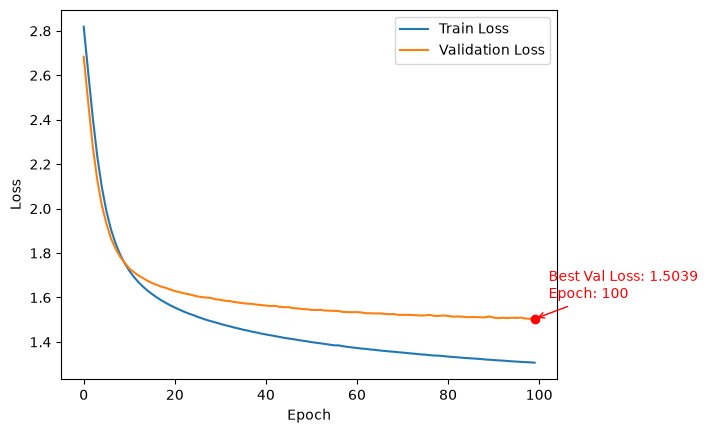

The parameter:
Epoch Number: 100
Embedding Dimension: 32
Hidden Dimension: 128
LSTM Layers: 2
dropout: 0.2
Learning Rate: 0.0001


In [27]:
plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

# Mark best validation loss
plt.scatter(best_epoch, best_val_loss, color="red", zorder=5)
plt.annotate(
    f"Best Val Loss: {best_val_loss:.4f}\nEpoch: {best_epoch + 1}",
    xy=(best_epoch, best_val_loss),
    xytext=(10, 15),
    textcoords="offset points",
    color="red",
    arrowprops=dict(arrowstyle="->", color="red")
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

print(f"The parameter:")
print(f"Epoch Number: {num_epochs}")
print(f"Embedding Dimension: {embed_dim}")
print(f"Hidden Dimension: {hidden_dim}")
print(f"LSTM Layers: {num_layers}")
print(f"dropout: {dropout}")
print(f"Learning Rate: {learning_rate}")

In [ ]:
vocab = {v: k for k, v in train_data.vocab.items()}
rows = []

for num in range(20):
    generated = generate(model, bos_id, eos_id, pad_id, max_length, device)
    sequence = ''.join(
        vocab[i] for i in generated
    )
    rows.append({'sequence': sequence})

pd.DataFrame(rows).to_csv("generated_LSTM.csv", index=False)